# 10 · From ideal QAOA to device-aware Aer

## Question

How does solution quality change when we move from an ideal quantum circuit to finite measurements and then to noisy hardware-like execution?

## Concept

**Exact classical → ideal quantum → finite shots → noisy simulation**

| Source of discrepancy | What it means here |
|---|---|
| Algorithmic approximation | Even with perfect gates, depth-one QAOA and its finite angle search leave probability on suboptimal strings. |
| Sampling uncertainty | Repeating the same measurement a finite number of times gives variable counts. |
| Hardware noise | Imperfect operations, relaxation and readout can change the distribution itself. |

These are separate effects to diagnose, not three numbers to add. Compare with exact enumeration first, then compare ideal probabilities with ideal shots, then hold the native circuit fixed and turn the noise model on.

**Informatics view.** A noisy simulator is still a classical computer numerically simulating a model of quantum hardware. Running the circuit on physical qubits is a qualitatively different experiment.

## Worked example · freeze the Phase 9 circuits

The [4×2 coupled chain](06_coupled_policy_map.ipynb) has exact optimum **1112**, score **13** (higher is better). We retain the [compact and one-hot encodings](08_encoding_comparison.ipynb), with four and eight logical qubits. Both use the exact $p=1$ circuits and grid-selected angles from [Notebook 09](09_hardware_aware_transpilation.ipynb). The fixed Ising coefficients below omit the constant phase. Displayed objectives are the original policy-map scores.

## Exercise / prediction

If shots increase from 100 to 10,000, how should the standard deviation of the optimal-frequency estimate change? Can more shots restore the ideal distribution if noise shifts it? Which encoding can produce an infeasible bit string?

In [1]:
import platform

import matplotlib.pyplot as plt
import numpy as np
import qiskit
import qiskit_aer
from IPython.display import Markdown, display
from qiskit import ClassicalRegister, QuantumCircuit, transpile
from qiskit.providers.fake_provider import GenericBackendV2
from qiskit.quantum_info import Operator, Statevector
from qiskit.transpiler import CouplingMap
from qiskit_aer import AerSimulator
from qiskit_aer.noise import NoiseModel

J = np.array([[4, 0], [1, 4], [4, 0], [0, 6]])
beta, exact_score = 2, 13
optimum = np.array([0, 0, 0, 1])
# Exact grid coordinates from Notebook 09, rather than rounded display angles.
models = {
    "Compact": ([-2, 1.5, -2, 3], {(0, 1): -1, (1, 2): -1, (2, 3): -1}, 1, 19),
    "One-hot": ([1.5, -0.5, -0.5, 1, 1, -1, -0.5, 2.5],
                {(0, 1): 10, (2, 3): 10, (4, 5): 10, (6, 7): 10,
                 (0, 3): 0.5, (1, 2): 0.5, (2, 5): 0.5,
                 (3, 4): 0.5, (4, 7): 0.5, (5, 6): 0.5}, 31, 21),
}
logical = {}
metrics = {}
for name, (fields, zz, g, t) in models.items():
    gamma, theta = g * (2*np.pi/32), t * (np.pi/24)
    width = len(fields)
    circuit = QuantumCircuit(width)
    circuit.h(range(width))
    for i, field in enumerate(fields):
        if field:
            circuit.rz(2*gamma*field, i)
    for (i, k), coupling in zz.items():
        circuit.rzz(2*gamma*coupling, i, k)
    circuit.rx(2*theta, range(width))
    logical[name] = circuit

    bits = (np.arange(2**width)[:, None] >> np.arange(width)) & 1
    rows = bits.reshape(-1, 4, width//4)
    feasible = (rows.sum(axis=2) == 1).all(axis=1) if width == 8 else np.ones(len(bits), dtype=bool)
    policies = rows.argmax(axis=2) if width == 8 else bits
    score = J[np.arange(4), policies].sum(axis=1) - beta*(policies[:, :-1] != policies[:, 1:]).sum(axis=1)
    optimal = feasible & (policies == optimum).all(axis=1)
    assert feasible.sum() == 16 and optimal.sum() == 1
    assert score[feasible].max() == exact_score and score[optimal].item() == exact_score

    # Check the frozen Hamiltonian, including the one-hot penalty, up to its constant.
    spins = 1 - 2*bits
    energy = spins @ fields
    for (i, k), coupling in zz.items():
        energy += coupling * spins[:, i] * spins[:, k]
    np.testing.assert_allclose(energy[feasible] - energy[optimal].item(),
                               exact_score - score[feasible])
    assert np.array_equal(energy == energy.min(), optimal)
    probability = Statevector.from_instruction(circuit).probabilities()
    metrics[name] = (feasible, optimal, score, probability)
    print(f"{name}: {width} qubits, γ={gamma:.9f}, θ={theta:.9f}")
    print(f"  Exact statevector: feasible {probability @ feasible:.2%}, optimal {probability @ optimal:.2%}")

print(f"Python {platform.python_version()}, Qiskit {qiskit.__version__}, Aer {qiskit_aer.__version__}, NumPy {np.__version__}")

Compact: 4 qubits, γ=0.196349541, θ=2.487094184
  Exact statevector: feasible 100.00%, optimal 19.87%
One-hot: 8 qubits, γ=6.086835766, θ=2.748893572
  Exact statevector: feasible 49.75%, optimal 5.98%
Python 3.15.2, Qiskit 2.6.2, Aer 0.18.4, NumPy 2.5.5


### Repeat ideal Aer sampling

Run five independent seeded batches per shot count. Report the sample standard deviation across repeats for optimal frequency, feasible frequency and conditional mean score. The best observed score is the maximum across all repeats at that shot count. A mean score is conditional on a valid map; report feasibility separately so invalid outcomes remain visible.

For an outcome with dimensionless probability $p_*$ and $N_\mathrm{shots}$ repetitions, the ideal standard deviation of its observed frequency is $\sqrt{p_*(1-p_*)/N_\mathrm{shots}}$. Five repeats give a rough empirical estimate. The same formula does not describe the best-of-batch score.

In [2]:
shot_counts = (100, 500, 1000, 4096, 10000)
seeds = (42, 43, 44, 45, 46)
ideal_aer = AerSimulator(method="statevector", max_parallel_threads=2)

def measure_logical(circuit, sites):
    measured = circuit.copy()
    measured.add_register(ClassicalRegister(len(sites), "outcome"))
    for i, site in enumerate(sites):
        measured.measure(site, i)
    return measured

def trials(simulator, circuit, width, shots):
    labels = [f"{i:0{width}b}" for i in range(2**width)]
    repeats = []
    for seed in seeds:
        counts = simulator.run(circuit, shots=shots, seed_simulator=seed).result().get_counts()
        sample = np.array([counts.get(label, 0) for label in labels])
        assert sample.sum() == shots
        repeats.append(sample/shots)
    return np.array(repeats)

def summarize(probabilities, name):
    feasible, optimal, score, _ = metrics[name]
    valid_mass = probabilities[:, feasible].sum(axis=1)
    numerator = probabilities[:, feasible] @ score[feasible]
    conditional = np.divide(numerator, valid_mass, out=np.full_like(numerator, np.nan),
                            where=valid_mass > 0)
    best = score[feasible & (probabilities > 0).any(axis=0)].astype(float).max(initial=-np.inf)
    return probabilities @ optimal, valid_mass, conditional, best

ideal_trials = {}
lines = ["| Encoding | Shots per repeat | Optimal % ± SD | Binomial SD (pp) | Feasible % ± SD | Mean feasible score ± SD | Best |",
         "|---|---:|---:|---:|---:|---:|---:|"]
for name, circuit in logical.items():
    measured = measure_logical(circuit, list(range(circuit.num_qubits)))
    p_opt = metrics[name][3] @ metrics[name][1]
    for shots in shot_counts:
        sampled = trials(ideal_aer, measured, circuit.num_qubits, shots)
        ideal_trials[name, shots] = sampled
        optimal_rate, feasible_rate, mean, best = summarize(sampled, name)
        lines.append(f"| {name} | {shots} | {100*optimal_rate.mean():.2f} ± {100*optimal_rate.std(ddof=1):.2f} | "
                     f"{100*np.sqrt(p_opt*(1-p_opt)/shots):.2f} | "
                     f"{100*feasible_rate.mean():.2f} ± {100*feasible_rate.std(ddof=1):.2f} | "
                     f"{mean.mean():.3f} ± {mean.std(ddof=1):.3f} | {best:g} |")
display(Markdown("\n".join(lines)))

| Encoding | Shots per repeat | Optimal % ± SD | Binomial SD (pp) | Feasible % ± SD | Mean feasible score ± SD | Best |
|---|---:|---:|---:|---:|---:|---:|
| Compact | 100 | 18.60 ± 4.45 | 3.99 | 100.00 ± 0.00 | 11.142 ± 0.300 | 13 |
| Compact | 500 | 20.28 ± 1.12 | 1.78 | 100.00 ± 0.00 | 11.275 ± 0.081 | 13 |
| Compact | 1000 | 20.64 ± 0.99 | 1.26 | 100.00 ± 0.00 | 11.276 ± 0.054 | 13 |
| Compact | 4096 | 20.29 ± 0.33 | 0.62 | 100.00 ± 0.00 | 11.265 ± 0.012 | 13 |
| Compact | 10000 | 20.07 ± 0.41 | 0.40 | 100.00 ± 0.00 | 11.258 ± 0.019 | 13 |
| One-hot | 100 | 6.00 ± 2.12 | 2.37 | 48.40 ± 7.89 | 8.748 ± 0.306 | 13 |
| One-hot | 500 | 6.32 ± 1.18 | 1.06 | 50.20 ± 3.39 | 8.675 ± 0.147 | 13 |
| One-hot | 1000 | 5.90 ± 0.89 | 0.75 | 49.30 ± 2.15 | 8.665 ± 0.135 | 13 |
| One-hot | 4096 | 5.72 ± 0.40 | 0.37 | 49.91 ± 0.75 | 8.673 ± 0.074 | 13 |
| One-hot | 10000 | 5.83 ± 0.28 | 0.24 | 49.87 ± 0.51 | 8.641 ± 0.043 | 13 |

### Device-aware Aer · hold the compiled circuit fixed

Recreate the synthetic eight-site bidirectional line from Notebook 09. Compile level 1 with identity placement, BasicSwap and transpiler seed 42. The compact circuit uses four sites, depth 17 and six CX gates. One-hot uses eight sites, depth 52 and 42 CX gates, following eight pre-translation SWAPs.

The circuit target has no noise properties. A second [GenericBackendV2](https://quantum.cloud.ibm.com/docs/en/api/qiskit/qiskit.providers.fake_provider.GenericBackendV2) with the same topology, basis and seed generates synthetic gate errors and durations, qubit relaxation times and readout errors. Aer derives the noise model [1] from those properties, with depolarization, thermal relaxation, and readout error enabled and thermal temperature set to zero. There are no custom gate durations. The code prints every property used by the executed gate/site combinations. These seeded synthetic properties are **representative noise, not calibration data for any actual QPU**.

**Physics / quantum view.** A density matrix describes a probabilistic mixture of quantum states. Aer propagates it through the modeled channels and samples the measured bits. Measure final physical sites into logical-order classical bits, so a layout permutation cannot look like noise. Run a matched noiseless control on exactly the same native circuit.

In [3]:
basis = ["rz", "sx", "x", "cx"]
line = CouplingMap.from_line(8)
target = GenericBackendV2(8, basis_gates=basis.copy(), coupling_map=line, seed=42, noise_info=False)
synthetic = GenericBackendV2(8, basis_gates=basis.copy(), coupling_map=line, seed=42, noise_info=True)
noise = NoiseModel.from_backend(synthetic, gate_error=True, thermal_relaxation=True,
                                readout_error=True, temperature=0)
clean_density = AerSimulator(method="density_matrix", max_parallel_threads=2)
noisy_density = AerSimulator(method="density_matrix", noise_model=noise, max_parallel_threads=2)
common_shots = 4096
compiled_clean, compiled_noisy = {}, {}
used = set()
print("Noise source:", synthetic.name, "| generated seed: 42 | noisy instructions:", noise.noise_instructions)
for name, circuit in logical.items():
    width = circuit.num_qubits
    mapped = transpile(circuit, backend=target, initial_layout=list(range(width)),
                       routing_method="basic", seed_transpiler=42, optimization_level=1,
                       qubits_initially_zero=False)
    padded = QuantumCircuit(mapped.num_qubits)
    padded.compose(circuit, qubits=range(width), inplace=True)
    assert Operator.from_circuit(mapped).equiv(Operator(padded))
    assert (mapped.depth(), mapped.count_ops().get("cx", 0)) == ((17, 6) if width == 4 else (52, 42))
    sites = mapped.layout.final_index_layout(filter_ancillas=True)
    measured = measure_logical(mapped, sites)
    used.update((item.operation.name, tuple(measured.find_bit(q).index for q in item.qubits))
                for item in measured.data)
    compiled_clean[name] = trials(clean_density, measured, width, common_shots)
    compiled_noisy[name] = trials(noisy_density, measured, width, common_shots)
    print(f"{name}: sites {sites}; compiled depth {mapped.depth()}; CX {mapped.count_ops()['cx']}")

print("Synthetic qubit properties (T1/T2 in seconds, frequency in Hz)")
for i, prop in enumerate(synthetic.target.qubit_properties):
    print(f"  {i}: T1={prop.t1!r}, T2={prop.t2!r}, frequency={prop.frequency!r}")
print("Synthetic instruction properties used (duration in seconds, error as probability)")
for gate, sites in sorted(used):
    prop = synthetic.target[gate][sites]
    print(f"  {gate}{sites}: duration={prop.duration!r}, error={prop.error!r}")

Noise source: generic_backend_8q | generated seed: 42 | noisy instructions: ['cx', 'measure', 'reset', 'sx', 'x']


Compact: sites [0, 1, 2, 3]; compiled depth 17; CX 6


One-hot: sites [1, 0, 3, 2, 6, 4, 5, 7]; compiled depth 52; CX 42
Synthetic qubit properties (T1/T2 in seconds, frequency in Hz)
  0: T1=0.00017739560485559633, T2=0.00014388784397520525, frequency=5429298959.955691
  1: T1=0.0001697368029059364, T2=0.00010941773478876496, frequency=5487811175.818378
  2: T1=0.0001761139701990353, T2=0.0001786064305276954, frequency=5064056816.337773
  3: T1=0.00014503859378955673, T2=0.00013707980242325812, frequency=5463382494.424301
  4: T1=0.00016438651200806646, T2=0.000182276161327083, frequency=5221707099.413666
  5: T1=0.0001227238721784777, T2=0.0001554584787015835, frequency=5031908628.052088
  6: T1=0.00018276311719925823, T2=0.0001631664399122065, frequency=5379043870.042686
  7: T1=0.00013545259681298685, T2=0.00019706980243949034, frequency=5446560560.6610985
Synthetic instruction properties used (duration in seconds, error as probability)
  cx(0, 1): duration=4.5621000000000003e-07, error=0.00284801856780494
  cx(1, 0): duration=1.94472e

## Result · compare the same objective

The exact solver returns one optimal map without a measurement distribution. The statevector rows report exact probabilities and the best score with nonzero support. Sampled rows average frequencies and conditional scores over five repeats. The best sample is taken across all repeats. The gap is the optimum minus the best supported or sampled score. A zero best-score gap can coexist with low optimal frequency.

| Encoding | Method | Exact optimum | Best | Gap | Optimal | Feasible | Mean feasible score | p | Shots × repeats |
|---|---|---:|---:|---:|---:|---:|---:|---:|---|
| Both | Exact classical | 13 | 13 | 0 | — | — | — | — | — |
| Compact | Ideal statevector | 13 | 13 | 0 | 19.87% | 100.00% | 11.250 | 1 | — |
| Compact | Ideal Aer | 13 | 13 | 0 | 20.29% | 100.00% | 11.265 | 1 | 4096 × 5 |
| Compact | Mapped Aer, noise off | 13 | 13 | 0 | 20.29% | 100.00% | 11.265 | 1 | 4096 × 5 |
| Compact | Mapped Aer, noise on | 13 | 13 | 0 | 20.19% | 100.00% | 11.188 | 1 | 4096 × 5 |
| One-hot | Ideal statevector | 13 | 13 | 0 | 5.98% | 49.75% | 8.674 | 1 | — |
| One-hot | Ideal Aer | 13 | 13 | 0 | 5.72% | 49.91% | 8.673 | 1 | 4096 × 5 |
| One-hot | Mapped Aer, noise off | 13 | 13 | 0 | 6.13% | 49.58% | 8.726 | 1 | 4096 × 5 |
| One-hot | Mapped Aer, noise on | 13 | 13 | 0 | 5.17% | 43.59% | 8.695 | 1 | 4096 × 5 |

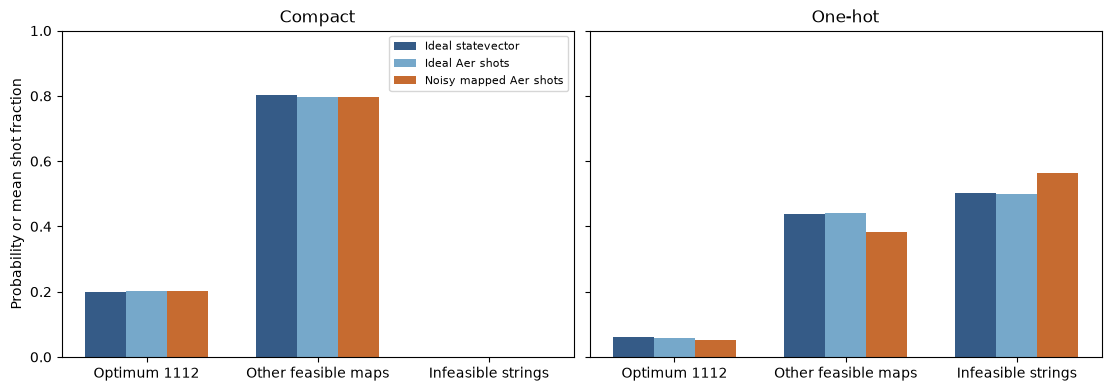

In [4]:
lines = ["| Encoding | Method | Exact optimum | Best | Gap | Optimal | Feasible | Mean feasible score | p | Shots × repeats |",
         "|---|---|---:|---:|---:|---:|---:|---:|---:|---|",
         "| Both | Exact classical | 13 | 13 | 0 | — | — | — | — | — |"]
for name, (_, _, _, probability) in metrics.items():
    comparisons = [
        ("Ideal statevector", probability[None, :], "—"),
        ("Ideal Aer", ideal_trials[name, common_shots], "4096 × 5"),
        ("Mapped Aer, noise off", compiled_clean[name], "4096 × 5"),
        ("Mapped Aer, noise on", compiled_noisy[name], "4096 × 5"),
    ]
    for label, sample, shots in comparisons:
        optimal_rate, feasible_rate, mean, best = summarize(sample, name)
        lines.append(f"| {name} | {label} | {exact_score} | {best:g} | {exact_score-best:g} | "
                     f"{optimal_rate.mean():.2%} | {feasible_rate.mean():.2%} | {mean.mean():.3f} | 1 | {shots} |")
display(Markdown("\n".join(lines)))

categories = ["Optimum 1112", "Other feasible maps", "Infeasible strings"]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True, layout="constrained")
for ax, (name, (feasible, optimal, _, probability)) in zip(axes, metrics.items(), strict=True):
    masks = (optimal, feasible & ~optimal, ~feasible)
    for i, (label, distribution) in enumerate([
        ("Ideal statevector", probability),
        ("Ideal Aer shots", ideal_trials[name, common_shots].mean(axis=0)),
        ("Noisy mapped Aer shots", compiled_noisy[name].mean(axis=0)),
    ]):
        ax.bar(np.arange(3) + (i-1)*0.24, [distribution[mask].sum() for mask in masks],
               width=0.24, label=label, color=("#355b87", "#76a8ca", "#c66b30")[i])
    ax.set(title=name, ylim=(0, 1), xticks=range(3), xticklabels=categories)
axes[0].set_ylabel("Probability or mean shot fraction")
axes[0].legend(fontsize=8)
plt.show()

**Exercise check.** The binomial standard deviation should shrink by a factor of ten. More shots narrow the uncertainty around the distribution being sampled. Every four-bit compact string decodes to a valid map here, so infeasible mass is zero even with noise.

**Why it matters here.** Level-1 mapping exposes one-hot to more CX gates, a deeper circuit, and routing absent in compact. Those differences motivate measuring noise sensitivity. This comparison varies encoding, circuit, layout, and error locations together, so the measured shifts cannot be attributed to individual SWAPs or any single error source.

## Takeaway

Exact enumeration establishes what score is possible. Ideal simulation establishes what this circuit tends to produce. Finite shots add uncertainty to that estimate. Noise changes the distribution being estimated.

## Presentation asset

Use the sequence **exact optimum → ideal QAOA → finite shots → noise**, paired with the three-category distribution figure. The infeasible category keeps one-hot constraint violations visible.

MkDocs topic for this notebook: `docs/simulation.md`.

## Next step · keep the benchmark fixed

For `11_first_qpu_execution.ipynb`, reuse the instance, objective, decoder, fixed angles and shot reporting. Use the same compilation methodology where the device permits it, and simulate the actual submitted native circuit to make the ideal/noisy/QPU comparison interpretable.

| Record | Quantities |
|---|---|
| Solution | Best objective, gap from 13, optimal frequency, feasible frequency, and conditional mean score |
| Resources | Logical and active physical qubits, transpiled depth, two-qubit gate count, QAOA depth, shots |
| Execution | Backend, calibration date if available, job identifier, execution time, and software versions |

A real run fills these execution fields when it happens.

### References

[1] Qiskit Aer, [NoiseModel and backend-derived errors](https://qiskit.github.io/qiskit-aer/stubs/qiskit_aer.noise.NoiseModel.html), version 0.18.4.